# TCC: Previsão de Inadimplência em Concessão de Crédito

**Metodologia:** CRISP-DM

---

## Fases 1 e 2: Entendimento do Negócio e Entendimento dos Dados (*Data Understanding*)

Este *notebook* inicial tem como objetivo a exploração e a compreensão do conjunto de dados oriundo da plataforma *Lending Club*. O foco aqui não é a modelagem, mas sim entender a estrutura das variáveis, a distribuição da nossa classe alvo (inadimplentes vs. adimplentes) e mapear a qualidade dos dados (valores nulos, tipos de dados e anomalias).

---
### 1. Carga Inicial e Inspeção da Estrutura
Nesta etapa, realizamos a importação da base de dados otimizada. Utilizaremos a biblioteca **Polars** para carregar o conjunto de dados previamente estruturado no formato **Parquet**. 

Essa decisão arquitetural permite o processamento de toda a volumetria histórica de dados (eliminando a necessidade de amostragem reduzida) e garante a integridade da tipagem das variáveis financeiras para as etapas de modelagem.

In [34]:
import polars as pl

# Caminho do arquivo Parquet JÁ PROCESSADO (pós-limpeza e filtros de status)
parquet_path = r'DataSet_Loan\base_credito_tcc.parquet'

# Carga instantânea dos dados para a memória
loan_data = pl.read_parquet(parquet_path)
df = loan_data

# Exibindo as primeiras linhas para validação visual da estrutura
loan_data.head()

loan_amnt,term,int_rate,grade,annual_inc,dti,emp_length,home_ownership,fico_range_low,fico_range_high,open_acc,pub_rec,revol_util,total_acc,mort_acc,inq_last_6mths,pub_rec_bankruptcies,issue_d,target
f64,str,f64,str,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,i8
3600.0,""" 36 months""",13.99,"""C""",55000.0,5.91,"""10+ years""","""MORTGAGE""",675.0,679.0,7.0,0.0,29.7,13.0,1.0,1.0,0.0,"""Dec-2015""",0
24700.0,""" 36 months""",11.99,"""C""",65000.0,16.06,"""10+ years""","""MORTGAGE""",715.0,719.0,22.0,0.0,19.2,38.0,4.0,4.0,0.0,"""Dec-2015""",0
20000.0,""" 60 months""",10.78,"""B""",63000.0,10.78,"""10+ years""","""MORTGAGE""",695.0,699.0,6.0,0.0,56.2,18.0,5.0,0.0,0.0,"""Dec-2015""",0
10400.0,""" 60 months""",22.45,"""F""",104433.0,25.37,"""3 years""","""MORTGAGE""",695.0,699.0,12.0,0.0,64.5,35.0,6.0,3.0,0.0,"""Dec-2015""",0
11950.0,""" 36 months""",13.44,"""C""",34000.0,10.2,"""4 years""","""RENT""",690.0,694.0,5.0,0.0,68.4,6.0,0.0,0.0,0.0,"""Dec-2015""",0


### 1.1. Dimensões, Tipagem e Integridade dos Dados
Com a base consolidada em memória, verificamos o volume total de registros retidos após a limpeza inicial, o schema de dados inferido e a presença de dados faltantes (nulos).

In [35]:
# 1. Dimensões da Base
print(f"Total de Clientes (Linhas): {loan_data.height}")
print(f"Total de Atributos (Colunas): {loan_data.width}")

# 2. Valores Nulos
print("\n--- Contagem de Valores Nulos ---")
print(loan_data.null_count())

# 3. Tipagem (Schema)
print("\n--- Tipagem das Colunas ---")
for coluna, tipo in loan_data.schema.items():
    print(f"{coluna}: {tipo}")

Total de Clientes (Linhas): 1345310
Total de Atributos (Colunas): 19

--- Contagem de Valores Nulos ---
shape: (1, 19)
┌───────────┬──────┬──────────┬───────┬───┬────────────────┬────────────────────┬─────────┬────────┐
│ loan_amnt ┆ term ┆ int_rate ┆ grade ┆ … ┆ inq_last_6mths ┆ pub_rec_bankruptci ┆ issue_d ┆ target │
│ ---       ┆ ---  ┆ ---      ┆ ---   ┆   ┆ ---            ┆ es                 ┆ ---     ┆ ---    │
│ u32       ┆ u32  ┆ u32      ┆ u32   ┆   ┆ u32            ┆ ---                ┆ u32     ┆ u32    │
│           ┆      ┆          ┆       ┆   ┆                ┆ u32                ┆         ┆        │
╞═══════════╪══════╪══════════╪═══════╪═══╪════════════════╪════════════════════╪═════════╪════════╡
│ 0         ┆ 0    ┆ 0        ┆ 0     ┆ … ┆ 1              ┆ 697                ┆ 0       ┆ 0      │
└───────────┴──────┴──────────┴───────┴───┴────────────────┴────────────────────┴─────────┴────────┘

--- Tipagem das Colunas ---
loan_amnt: Float64
term: String
int_rate: Fl

### 1.2. Distribuição da Variável Alvo (Target)
O mapeamento da proporção entre bons pagadores (0) e inadimplentes (1) é essencial para validar o desbalanceamento natural do cenário de concessão de crédito, fator que guiará as estratégias de validação (como a estratificação) e a escolha de métricas de avaliação (Recall, F1-Score).

In [14]:
print("Distribuição de Inadimplência:\n")

distribuicao = (
    df['target'].value_counts(normalize=True)
    .with_columns((pl.col('proportion') * 100).alias('porcentagem (%)'))
)

print(distribuicao)

Distribuição de Inadimplência:

shape: (2, 3)
┌────────┬────────────┬─────────────────┐
│ target ┆ proportion ┆ porcentagem (%) │
│ ---    ┆ ---        ┆ ---             │
│ i8     ┆ f64        ┆ f64             │
╞════════╪════════════╪═════════════════╡
│ 0      ┆ 0.800374   ┆ 80.037389       │
│ 1      ┆ 0.199626   ┆ 19.962611       │
└────────┴────────────┴─────────────────┘


### 1.3. Divisão dos Dados e Separação Out-of-Time (OOT)

Para garantir o rigor metodológico e simular o cenário real de implantação do modelo em produção, a divisão dos dados adota uma abordagem híbrida, combinando separação cronológica e aleatória nas proporções 70/20/10:

* **Teste / Out-of-Time (10%):** Conjunto separado de forma estritamente cronológica, contendo as concessões de crédito mais recentes (`issue_d`). Esta partição permanece isolada durante todo o desenvolvimento para avaliar a estabilidade e a degradação preditiva do modelo ao longo do tempo.
* **Validação (20%):** Separado aleatoriamente a partir dos dados históricos remanescentes, utilizado para a calibração de hiperparâmetros e prevenção de *overfitting* durante o treino.
* **Treino (70%):** Base histórica principal, separada aleatoriamente em conjunto com a validação. É de uso exclusivo para o cálculo de *Weight of Evidence* (WoE), *Information Value* (IV), análise de importância das variáveis e treino dos algoritmos.

In [31]:
import polars as pl
from sklearn.model_selection import train_test_split

df_treated = (
    df.clone()
    .with_columns(
        pl.col("issue_d")
        .str.strip_chars()
        .str.strptime(pl.Date, format="%b-%Y")
        .alias("_issue_date")
    )
    .sort("_issue_date")
)

# Os 10% mais recentes formam o conjunto Out-of-Time (OOT).
split_index = int(df_treated.height * 0.90)
df_train_val = df_treated[:split_index]
df_test = df_treated[split_index:]

# Os 90% históricos são divididos aleatoriamente entre treino e validação,
# preservando a proporção da variável target.
df_train, df_val = train_test_split(
    df_train_val,
    test_size=(0.20 / 0.90),
    random_state=42,
    shuffle=True,
    stratify=df_train_val["target"].to_list()
)

# A coluna auxiliar de data não será usada como variável preditora.
df_train = df_train.drop("_issue_date")
df_val = df_val.drop("_issue_date")
df_test = df_test.drop("_issue_date")

print(f"Train set shape: {df_train.shape}")
print(f"Validation set shape: {df_val.shape}")
print(f"Test/OOT set shape: {df_test.shape}")
print(f"Período histórico: {df_train_val['issue_d'].min()} até {df_train_val['issue_d'].max()}")
print(f"Período OOT: {df_test['issue_d'].min()} até {df_test['issue_d'].max()}")

Train set shape: (941717, 19)
Validation set shape: (269062, 19)
Test/OOT set shape: (134531, 19)
Período histórico: Apr-2008 até Sep-2016
Período OOT: Apr-2018 até Sep-2018


### 1.4. Matriz de correlação

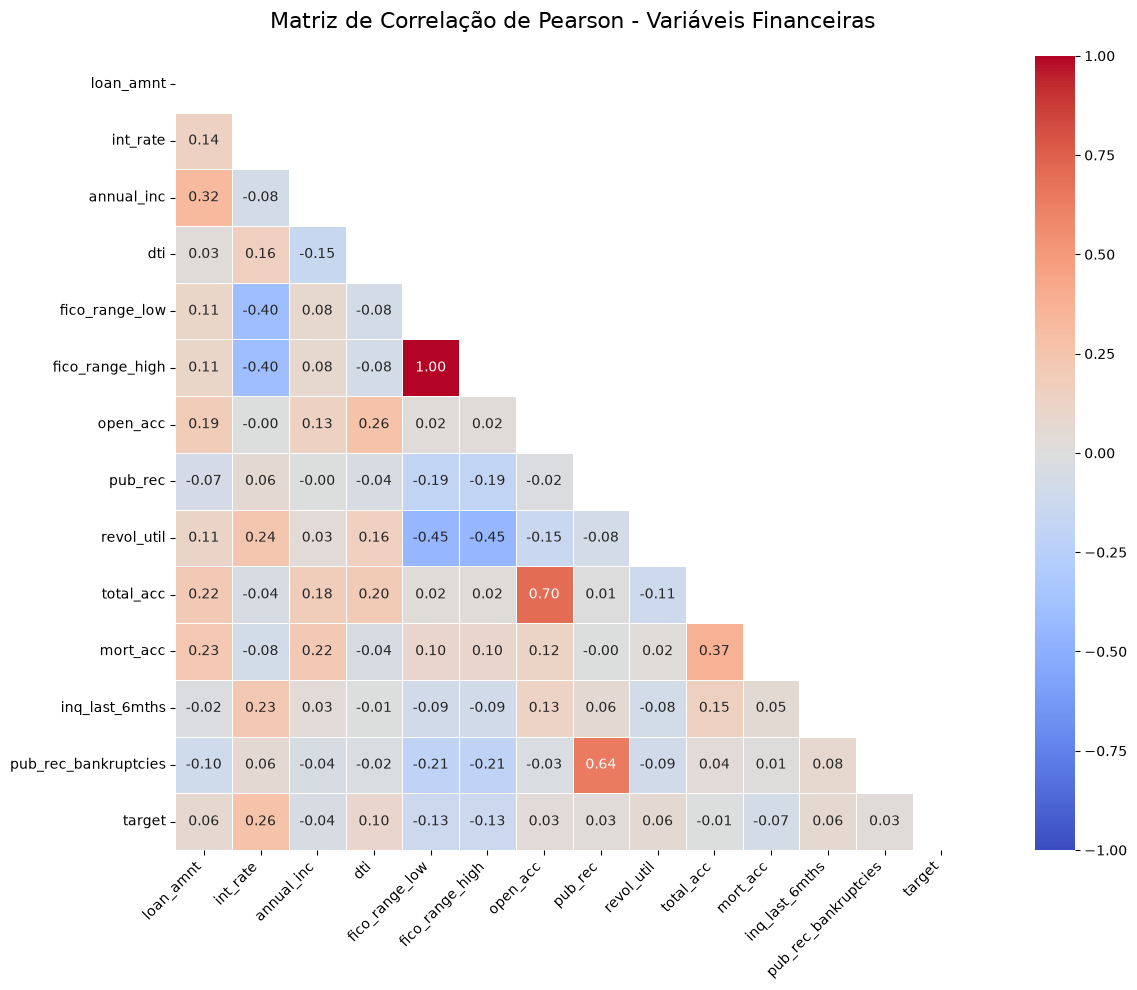


=== RANKING DE CORRELAÇÃO COM A INADIMPLÊNCIA (TARGET) ===
(Valores próximos de 1 ou -1 são os mais fortes)
int_rate                0.261037
dti                     0.100129
inq_last_6mths          0.064728
loan_amnt               0.062624
revol_util              0.057272
open_acc                0.033635
pub_rec_bankruptcies    0.027460
pub_rec                 0.027402
total_acc              -0.005474
annual_inc             -0.041063
mort_acc               -0.072946
fico_range_high        -0.131692
fico_range_low         -0.131693
Name: target, dtype: float64


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import polars.selectors as cs

# Filtramos apenas as colunas numéricas do conjunto de treino e convertemos para Pandas para o Seaborn conseguir desenhar
numeric_df = df_train.select(cs.numeric()).to_pandas()

# Calculamos a correlação de Pearson
correlation_matrix = numeric_df.corr()


plt.figure(figsize=(14, 10))

# Criamos uma 'máscara' para apagar a metade de cima do gráfico
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Desenhando o mapa de calor com as cores (vermelho = correlação positiva, azul = negativa)
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
            vmin=-1, vmax=1, linewidths=0.5, square=True)

plt.title('Matriz de Correlação de Pearson - Variáveis Financeiras', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\n=== RANKING DE CORRELAÇÃO COM A INADIMPLÊNCIA (TARGET) ===")
print("(Valores próximos de 1 ou -1 são os mais fortes)")

# Pegamos a coluna target, tiramos ela mesma da lista e ordenamos do mais forte pro mais fraco
target_correlation = correlation_matrix['target'].drop('target').sort_values(ascending=False)

print(target_correlation)

### 1.5. Importância Não Linear de Variáveis Numéricas (Tree-based Importance)

Para garantir a robustez metodológica na seleção de atributos numéricos, optou-se por não depender exclusivamente da Matriz de Correlação de Pearson, uma vez que esta métrica clássica captura apenas relações lineares ou monotônicas. Como a modelagem preditiva deste trabalho utilizará algoritmos baseados em árvores de decisão (Random Forest e XGBoost), é necessário identificar variáveis que apresentem padrões não lineares complexos em relação à inadimplência.

Para mapear essas relações, aplicou-se o treinamento de um modelo baseline de Random Forest (max_depth=5) com o propósito exploratório de extrair a importância das variáveis. Este método quantifica o ganho de informação e a relevância real de cada atributo numérico na segregação das classes (adimplente vs. inadimplente), alinhando a etapa de seleção à natureza matemática dos preditores finais.

In [29]:
from sklearn.ensemble import RandomForestClassifier
import polars as pl
import pandas as pd

# Seleciona apenas colunas numéricas estritamente do conjunto de TREINO (excluindo a target)
numeric_df = df_train.select(pl.selectors.numeric())
numeric_features = [col for col in numeric_df.columns if col != 'target']

# Cria uma base temporária sem nulos apenas para o Scikit-Learn não falhar no treino
train_data_for_rf = df_train.select(numeric_features + ['target']).drop_nulls()

X = train_data_for_rf.select(numeric_features).to_pandas()
y = train_data_for_rf.select('target').to_pandas().values.ravel()

exploratory_rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
exploratory_rf.fit(X, y)

importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance (Tree-based)': exploratory_rf.feature_importances_
}).sort_values(by='Importance (Tree-based)', ascending=False)

print("\n--- Ranking de Importância (Random Forest) ---")
print(importances)


--- Ranking de Importância (Random Forest) ---
                 Feature  Importance (Tree-based)
1               int_rate                 0.590486
5        fico_range_high                 0.098779
3                    dti                 0.092147
4         fico_range_low                 0.082417
0              loan_amnt                 0.059426
10              mort_acc                 0.036701
2             annual_inc                 0.017865
11        inq_last_6mths                 0.011534
6               open_acc                 0.003766
8             revol_util                 0.003452
7                pub_rec                 0.001703
9              total_acc                 0.000917
12  pub_rec_bankruptcies                 0.000807


### 1.6. Análise de Poder Preditivo de Variáveis Categóricas (WoE e IV)

Para as variáveis categóricas (`grade`, `term`, `emp_length` e `home_ownership`), a avaliação do poder preditivo será conduzida por meio do cálculo de *Weight of Evidence* (WoE) e *Information Value* (IV). Esta abordagem, amplamente validada pela literatura de *credit scoring* (SIDDIQI, 2017), permite transformar categorias textuais em pesos matemáticos baseados no risco de crédito.

O *Information Value* (IV) consolida o WoE de todas as categorias de uma variável, resultando num valor único que define a força daquele atributo para o modelo. Adotaremos a regra de bolso padrão do mercado financeiro para a seleção:
* **IV < 0.02:** Poder preditivo inútil (Descartar)
* **0.02 a 0.1:** Poder preditivo fraco
* **0.1 a 0.3:** Poder preditivo médio
* **IV > 0.3:** Poder preditivo forte

**Rigor Metodológico e Prevenção de Vazamento de Dados:**
Para assegurar a validade científica da modelização e simular o comportamento real do algoritmo em produção, o cálculo das proporções do WoE e do IV é realizado **exclusivamente sobre o conjunto de treino** (`df_train`). Utilizar o conjunto completo de dados nesta fase configuraria o vazamento de informações (*data leakage*), o que inflacionaria artificialmente o desempenho do modelo na fase de teste. Os pesos calculados gerarão um dicionário estático que será posteriormente aplicado de forma isolada aos conjuntos de validação e teste.

In [30]:
import polars as pl

def calculate_woe_iv(df_polars, feature, target):
    # Calcula os totais de bons e maus no conjunto recebido (Treino)
    totals = df_polars.select([
        pl.col(target).sum().alias("total_bads"),
        (pl.len() - pl.col(target).sum()).alias("total_goods")
    ]).row(0)
    
    total_bads, total_goods = totals[0], totals[1]
    eps = 1e-6 # Evitar divisão por zero no logaritmo

    # Agrupa por categoria da variável e conta o volume de bons e maus
    grouped = df_polars.group_by(feature).agg([
        pl.len().alias("total_category"),
        pl.col(target).sum().alias("bads")
    ]).with_columns([
        (pl.col("total_category") - pl.col("bads")).alias("goods")
    ]).with_columns([
        (pl.col("goods") / total_goods).alias("pct_goods"),
        (pl.col("bads") / total_bads).alias("pct_bads")
    ]).with_columns([
        # Calcula o WoE e o IV da categoria
        (pl.col("pct_goods") / (pl.col("pct_bads") + eps)).log().alias("woe")
    ]).with_columns([
        ((pl.col("pct_goods") - pl.col("pct_bads")) * pl.col("woe")).alias("iv_category")
    ])

    total_iv = grouped.select(pl.col("iv_category").sum()).item()
    return total_iv, grouped.sort("woe")

categorical_features = ['grade', 'term', 'emp_length', 'home_ownership']

print("--- Poder Preditivo (Information Value - Siddiqi, 2017) ---")
print("Regra de bolso: > 0.3 (Forte) | 0.1 a 0.3 (Médio) | < 0.1 (Fraco)\n")

woe_dict = {}

for var in categorical_features:
    # Usamos df_train e não a base completa
    iv, detailed_table = calculate_woe_iv(df_train, var, 'target')
    print(f"Variável '{var}': IV = {iv:.4f}")
    
    woe_dict[var] = detailed_table

--- Poder Preditivo (Information Value - Siddiqi, 2017) ---
Regra de bolso: > 0.3 (Forte) | 0.1 a 0.3 (Médio) | < 0.1 (Fraco)

Variável 'grade': IV = 0.4659
Variável 'term': IV = 0.1865
Variável 'emp_length': IV = 0.0101
Variável 'home_ownership': IV = 0.0282
